# H2 Qiskit Runtime Energy Figure

This notebook generates the paper figure for the H2 Qiskit Runtime trace. It plots reported energy and reference ground energy, then places a `√` marker above the two energy lines for each iteration that passes the Python trace checker.


In [1]:
from pathlib import Path
import os
import sys


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'python 2.0' / 'trace_checker.py').exists() and (candidate / 'traces').exists():
            return candidate
    raise RuntimeError('Could not find project root from {}'.format(start))


ROOT = find_project_root(Path.cwd())
TRACE_PATH = ROOT / 'traces' / 'myTests' / 'h2_ibm_runtime_paper.jsonl'
OUTPUT_SVG = ROOT / 'paper_artifacts' / 'h2_runtime_energy_verified_checkmarks.svg'

os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'paper_artifacts' / '.matplotlib'))

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

PYTHON20 = ROOT / 'python 2.0'
if str(PYTHON20) not in sys.path:
    sys.path.insert(0, str(PYTHON20))

from trace_checker import check_record, check_trace, load_trace

TRACE_PATH, OUTPUT_SVG


Matplotlib is building the font cache; this may take a moment.


(PosixPath('/Users/rome/Desktop/Formal Verification on VQE/code/Dafny + Python trace checker/traces/myTests/h2_ibm_runtime_paper.jsonl'),
 PosixPath('/Users/rome/Desktop/Formal Verification on VQE/code/Dafny + Python trace checker/paper_artifacts/h2_runtime_energy_verified_checkmarks.svg'))

In [2]:
TOLERANCE = 1e-9

records, load_violations = load_trace(TRACE_PATH)
if load_violations:
    messages = [f'line {item.line} [{item.property}] {item.message}' for item in load_violations]
    raise RuntimeError('Trace load failed:\n' + '\n'.join(messages))
if not records:
    raise RuntimeError(f'Trace contains no records: {TRACE_PATH}')

trace_result = check_trace(TRACE_PATH, TOLERANCE)
line_failures = {}
for violation in trace_result.violations:
    line_failures.setdefault(violation.line, set()).add(violation.property)

for line, record in enumerate(records, 1):
    for violation in check_record(record, line, TOLERANCE):
        line_failures.setdefault(line, set()).add(violation.property)

iterations = [int(record['iter']) for record in records]
reported_energy = [float(record['reported_energy']) for record in records]
reference_ground_energy = float(records[0]['reference_ground_energy'])
iteration_passed = [not line_failures.get(line) for line in range(1, len(records) + 1)]

print(f'Trace: {TRACE_PATH}')
print(f'Records: {len(records)}')
print(f'Full-trace checker result: {"PASS" if trace_result.valid else "FAIL"}')
print(f'Per-iteration markers: {sum(iteration_passed)}/{len(iteration_passed)} pass')


Trace: /Users/rome/Desktop/Formal Verification on VQE/code/Dafny + Python trace checker/traces/myTests/h2_ibm_runtime_paper.jsonl
Records: 25
Full-trace checker result: PASS
Per-iteration markers: 25/25 pass


Wrote /Users/rome/Desktop/Formal Verification on VQE/code/Dafny + Python trace checker/paper_artifacts/h2_runtime_energy_verified_checkmarks.png


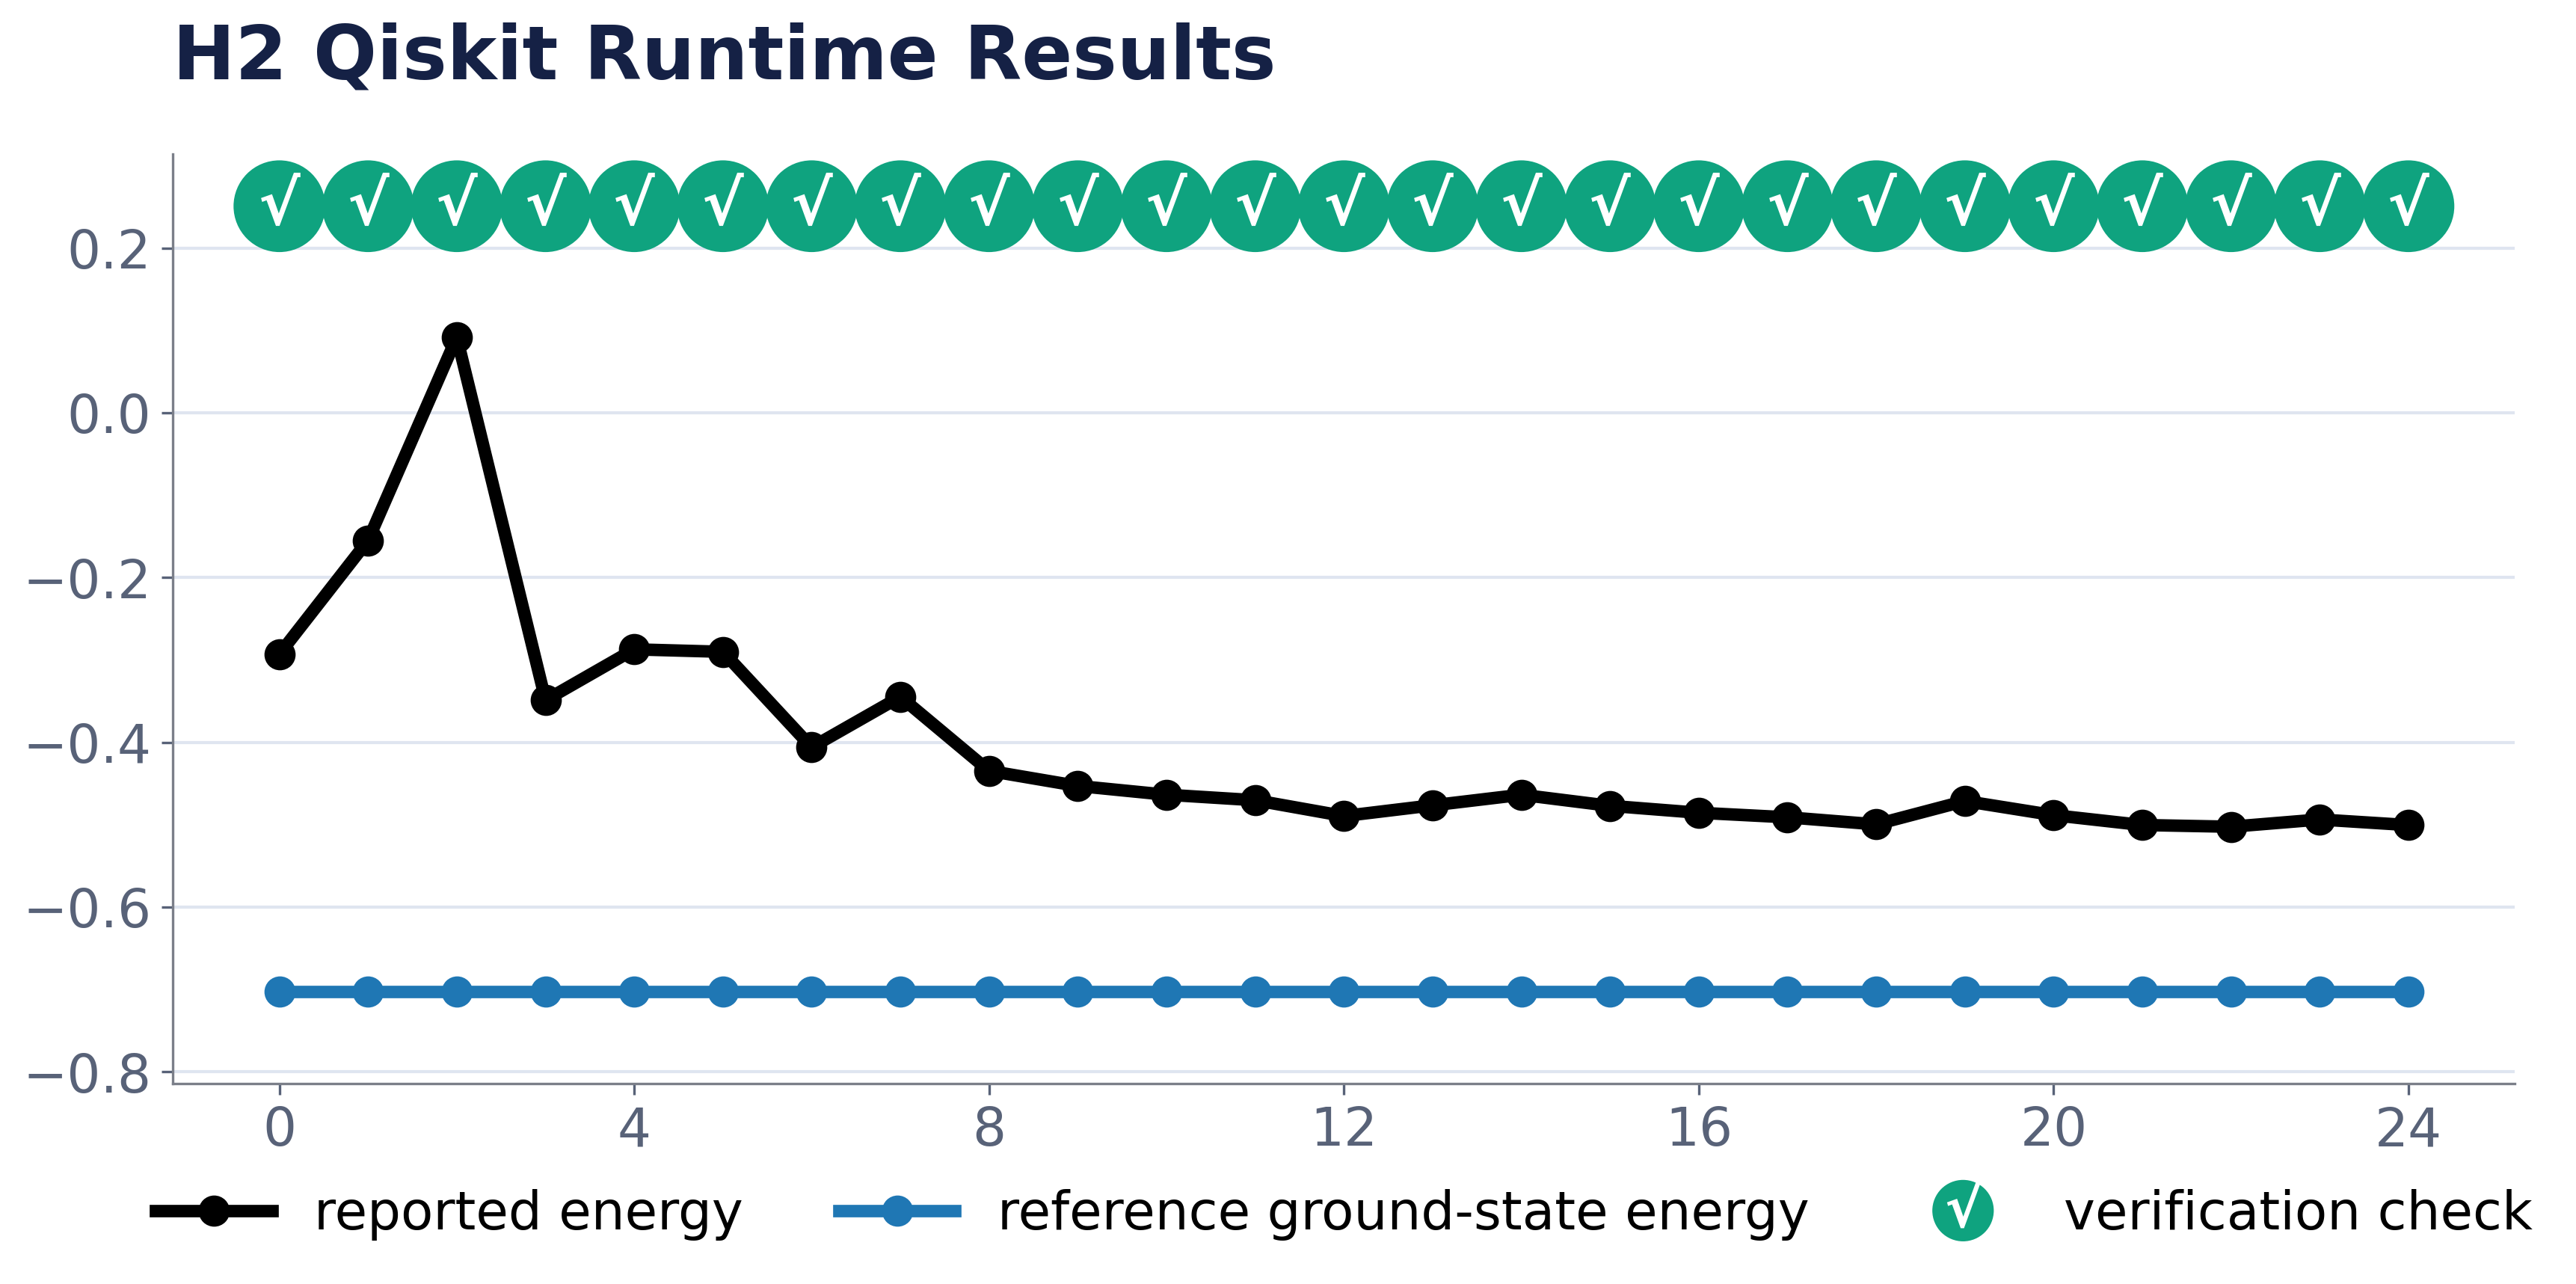

In [27]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.legend_handler import HandlerBase
from matplotlib.patches import Circle
from matplotlib.text import Text

navy = '#18275b'
green = '#0fa37f'
red = '#c23b3b'
grid = '#dfe5f0'
text = '#586278'
title = '#152145'

TITLE_SIZE = 24
TICK_SIZE = 17
LEGEND_SIZE = 17
MARK_SIZE = 20

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.titlesize': TITLE_SIZE,
    'axes.titleweight': 'bold',
    'xtick.labelsize': TICK_SIZE,
    'ytick.labelsize': TICK_SIZE,
    'legend.fontsize': LEGEND_SIZE,
})

fig, ax = plt.subplots(figsize=(12, 7.4), dpi=300)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.plot(
    iterations,
    reported_energy,
    color='black',
    marker='o',
    linewidth=4,
    markersize=9,
    label='reported energy',
)

ax.plot(
    iterations,
    [reference_ground_energy] * len(iterations),
    color='#1f77b4',
    marker='o',
    linewidth=4,
    markersize=9,
    label='reference ground-state energy',
)

energy_min = min(min(reported_energy), reference_ground_energy)
energy_max = max(max(reported_energy), reference_ground_energy)
span = max(energy_max - energy_min, 0.1)
lower = energy_min - 0.14 * span
upper = energy_max + 0.28 * span
verification_y = upper - 0.08 * span

ax.set_ylim(lower, upper)
ax.yaxis.set_major_locator(MaxNLocator(nbins=6))
ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=min(8, len(iterations))))
ax.grid(axis='y', color=grid, linewidth=1)

ax.set_title(
    'H2 Qiskit Runtime Results',
    loc='left',
    color=title,
    pad=24,
    fontsize=TITLE_SIZE,
    fontweight='bold',
)

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

ax.spines['left'].set_color('#7b7f89')
ax.spines['bottom'].set_color('#7b7f89')
ax.tick_params(colors=text, labelsize=TICK_SIZE)

for x, ok in zip(iterations, iteration_passed):
    ax.text(
        x,
        verification_y,
        '√' if ok else '×',
        ha='center',
        va='center',
        color='white',
        fontsize=MARK_SIZE,
        fontweight='bold',
        bbox={
            'boxstyle': 'circle,pad=0.25',
            'facecolor': green if ok else red,
            'edgecolor': 'none',
        },
        zorder=6,
    )

class CheckCircleHandle:
    pass


class HandlerCheckCircle(HandlerBase):
    def create_artists(self, legend, orig_handle, xdescent, ydescent, width, height, fontsize, trans):
        cx = xdescent + width / 2
        cy = ydescent + height / 2

        radius = fontsize * 0.58

        circle = Circle(
            (cx, cy),
            radius,
            facecolor=green,
            edgecolor='none',
            transform=trans,
        )

        check = Text(
            cx,
            cy,
            '√',
            color='white',
            fontsize=fontsize * 1.08,
            fontweight='bold',
            ha='center',
            va='center',
            transform=trans,
        )

        return [circle, check]


verification_handle = CheckCircleHandle()

handles, labels = ax.get_legend_handles_labels()
handles.append(verification_handle)
labels.append('verification check')

ax.legend(
    handles,
    labels,
    loc='lower center',
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False,
    handler_map={CheckCircleHandle: HandlerCheckCircle()},
    handlelength=2.2,
    handletextpad=0.8,
    columnspacing=1.8,
    fontsize=LEGEND_SIZE,
)

fig.subplots_adjust(left=0.10, right=0.97, top=0.84, bottom=0.28)

OUTPUT_PNG = OUTPUT_SVG.with_suffix('.png')

OUTPUT_PNG.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_PNG, format='png', dpi=300, bbox_inches='tight')
print(f'Wrote {OUTPUT_PNG}')

try:
    from IPython.display import Image, display
    display(Image(filename=str(OUTPUT_PNG)))
except Exception:
    pass